# 05 · Binomial negativa (Mhetre y Thube, 2023)
Tarea 1. ¿La sobredispersión de los conteos justifica una binomial negativa en lugar del Poisson del baseline?
- `N_ACC`: conteo de accidentes por departamento y día (D² de Poisson).
- `HAY_FATAL`: se modela `N_FATALES` y se usa P(≥ 1 fatal) = 1 − P(0) (PR-AUC).
Misma validación que `02_modelos.ipynb`: CV temporal sobre el train; el holdout abr–sep 2021 se usa una sola vez al final.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import gammaln
from sklearn.model_selection import GridSearchCV

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import models as M, evaluation as E

warnings.filterwarnings("ignore")
PLOTS = ROOT / "results" / "plots"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FILAS = []   # filas nuevas para results/metrics.csv


def resumen(res):
    # media y desviación estándar por modelo
    return pd.DataFrame({k: v.agg(["mean", "std"]).T.stack() for k, v in res.items()}).T.round(4)

In [2]:
panel = M.cargar_panel()
tr1 = panel[panel.FECHA < M.INICIO_HOLDOUT].reset_index(drop=True)
te1 = panel[panel.FECHA >= M.INICIO_HOLDOUT].reset_index(drop=True)
COLS1 = M.columnas(M.GRUPOS_T1)
X1 = COLS1[0] + COLS1[1]
FOLDS1 = list(E.cv_temporal(tr1.FECHA))

print(f"Train: {len(tr1):,} filas · holdout: {len(te1):,} filas")
print(f"N_ACC     · media {panel.N_ACC.mean():.3f} · varianza {panel.N_ACC.var():.3f} · var/media {panel.N_ACC.var() / panel.N_ACC.mean():.2f}")
print(f"N_FATALES · media {panel.N_FATALES.mean():.3f} · varianza {panel.N_FATALES.var():.3f} · var/media {panel.N_FATALES.var() / panel.N_FATALES.mean():.2f}")

Train: 10,776 filas · holdout: 4,392 filas
N_ACC     · media 0.528 · varianza 0.873 · var/media 1.66
N_FATALES · media 0.062 · varianza 0.065 · var/media 1.06


In [3]:
busqueda = GridSearchCV(M.binomial_negativa(COLS1), {"reg__l2": [1e-4, 1e-3, 1e-2, 1e-1, 1.0]},
                        cv=FOLDS1, scoring="neg_mean_poisson_deviance").fit(tr1[X1], tr1.N_ACC)
display(pd.DataFrame(busqueda.cv_results_)[["param_reg__l2", "mean_test_score", "std_test_score"]].round(4))
L2 = busqueda.best_params_["reg__l2"]
print("l2 elegido:", L2)

,param_reg__l2,mean_test_score,std_test_score
0,0.0001,-0.9517,0.0487
1,0.0010,-0.9496,0.0470
2,0.0100,-0.9794,0.0450
3,0.1000,-1.0182,0.0610
4,1.0000,-1.0459,0.0629


l2 elegido: 0.001


In [4]:
def ingenuo_conteo(df, col):
    return df[col].fillna(df.N_ACC_M7)

res = {"Ingenuo · media 28 días": pd.DataFrame([E.metricas_conteo(tr1.N_ACC.iloc[b], ingenuo_conteo(tr1.iloc[b], "N_ACC_M28")) for _, b in FOLDS1]),
       "Baseline · Poisson": E.cv_puntajes(M.poisson(COLS1), tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo),
       "Binomial negativa": E.cv_puntajes(M.binomial_negativa(COLS1, l2=L2), tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo)}
display(resumen(res))
print("BN − Poisson (D²):", E.comparacion_pareada(res["Binomial negativa"].d2_poisson, res["Baseline · Poisson"].d2_poisson))
print("BN − ingenuo (D²):", E.comparacion_pareada(res["Binomial negativa"].d2_poisson, res["Ingenuo · media 28 días"].d2_poisson))
for n, r in res.items():
    FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": n, "validacion": "CV temporal (5 pliegues)", **r.mean().to_dict()})

poisson_dev         d2_poisson             mae  \
                               mean     std       mean     std    mean   
Ingenuo · media 28 días      0.9984  0.0469     0.2173  0.0525  0.5464   
Baseline · Poisson           0.9489  0.0529     0.2562  0.0535  0.5685   
Binomial negativa            0.9496  0.0526     0.2556  0.0545  0.5689   

                                   rmse          
                            std    mean     std  
Ingenuo · media 28 días  0.0623  0.7892  0.0802  
Baseline · Poisson       0.0339  0.7923  0.0584  
Binomial negativa        0.0336  0.7932  0.0580

BN − Poisson (D²): -0.001 (IC95% aprox. -0.002 a +0.000), mejor en 1 de 5 pliegues
BN − ingenuo (D²): +0.038 (IC95% aprox. +0.023 a +0.053), mejor en 5 de 5 pliegues


In [5]:
bn = M.binomial_negativa(COLS1, l2=L2).fit(tr1[X1], tr1.N_ACC)
pois = M.poisson(COLS1).fit(tr1[X1], tr1.N_ACC)
y, mu_p, n = tr1.N_ACC.to_numpy(), pois.predict(tr1[X1]), len(tr1)
ll_p = float((y * np.log(mu_p) - mu_p - gammaln(y + 1)).sum())   # log-verosimilitud de Poisson
k_p = pois[-1].coef_.size + 1                                     # coeficientes + intercepto
r = bn[-1]
lr = 2 * (r.loglik_ - ll_p)                                       # razón de verosimilitudes (H0: alpha = 0)
display(pd.DataFrame({"log-verosimilitud": [ll_p, r.loglik_], "AIC": [2 * k_p - 2 * ll_p, r.aic_],
                      "BIC": [k_p * np.log(n) - 2 * ll_p, r.bic_]}, index=["Poisson", "Binomial negativa"]).round(1))
print(f"alpha = {r.alpha_:.3f} (convergió: {r.convergio_}) · razón de verosimilitudes = {lr:.1f}")

,log-verosimilitud,AIC,BIC
Poisson,-8364.0,16816.1,17136.6
Binomial negativa,-8354.3,16798.7,17126.5


alpha = 0.100 (convergió: True) · razón de verosimilitudes = 19.4


In [6]:
hold = {"Ingenuo · media 28 días": E.metricas_conteo(te1.N_ACC, ingenuo_conteo(te1, "N_ACC_M28")),
        "Baseline · Poisson": E.metricas_conteo(te1.N_ACC, pois.predict(te1[X1])),
        "Binomial negativa": E.metricas_conteo(te1.N_ACC, bn.predict(te1[X1]))}
display(pd.DataFrame(hold).T.round(4))
for n_, r_ in hold.items():
    FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": n_, "validacion": "holdout abr-sep 2021", **r_})

,poisson_dev,d2_poisson,mae,rmse
Ingenuo · media 28 días,1.0019,0.2775,0.6046,0.8365
Baseline · Poisson,1.0170,0.2665,0.5896,0.8504
Binomial negativa,1.0150,0.2680,0.5897,0.8492


In [7]:
def metricas_fatal(y_fatales, prob):
    return E.metricas_binaria((np.asarray(y_fatales) > 0).astype(int), prob)

ingenuo_fatal = lambda df: 1 - np.exp(-df.N_FATALES_M28)
logit1 = M.logit(COLS1, class_weight=None)
resb = {"Ingenuo · fatales últimos 28 días": pd.DataFrame([E.metricas_binaria(tr1.HAY_FATAL.iloc[b], ingenuo_fatal(tr1.iloc[b])) for _, b in FOLDS1]),
        "Baseline · Reg. logística": E.cv_puntajes(logit1, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True),
        "Binomial negativa (N_FATALES)": E.cv_puntajes(M.binomial_negativa(COLS1, l2=L2), tr1[X1], tr1.N_FATALES, FOLDS1, metricas_fatal, proba=True)}
display(resumen(resb))
print("BN − logística (PR-AUC):", E.comparacion_pareada(resb["Binomial negativa (N_FATALES)"].pr_auc, resb["Baseline · Reg. logística"].pr_auc))

bn_f = M.binomial_negativa(COLS1, l2=L2).fit(tr1[X1], tr1.N_FATALES)
print(f"alpha de N_FATALES = {bn_f[-1].alpha_:.4f}")
holdb = {"Ingenuo · fatales últimos 28 días": E.metricas_binaria(te1.HAY_FATAL, ingenuo_fatal(te1)),
         "Baseline · Reg. logística": E.metricas_binaria(te1.HAY_FATAL, logit1.fit(tr1[X1], tr1.HAY_FATAL).predict_proba(te1[X1])[:, 1]),
         "Binomial negativa (N_FATALES)": E.metricas_binaria(te1.HAY_FATAL, bn_f.predict_proba(te1[X1])[:, 1])}
display(pd.DataFrame(holdb).T.round(4))
for n_, r_ in resb.items():
    FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": n_, "validacion": "CV temporal (5 pliegues)", **r_.mean().to_dict()})
for n_, r_ in holdb.items():
    FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": n_, "validacion": "holdout abr-sep 2021", **r_})

pr_auc         roc_auc           brier  \
                                     mean     std    mean     std    mean   
Ingenuo · fatales últimos 28 días  0.1119  0.0178  0.6775  0.0140  0.0542   
Baseline · Reg. logística          0.1330  0.0279  0.7041  0.0254  0.0561   
Binomial negativa (N_FATALES)      0.1303  0.0258  0.7035  0.0209  0.0546   

                                          prevalencia          
                                      std        mean     std  
Ingenuo · fatales últimos 28 días  0.0067      0.0584  0.0081  
Baseline · Reg. logística          0.0076      0.0584  0.0081  
Binomial negativa (N_FATALES)      0.0066      0.0584  0.0081

BN − logística (PR-AUC): -0.003 (IC95% aprox. -0.008 a +0.002), mejor en 1 de 5 pliegues


alpha de N_FATALES = 0.0005


,pr_auc,roc_auc,brier,prevalencia
Ingenuo · fatales últimos 28 días,0.1313,0.6887,0.0618,0.0676
Baseline · Reg. logística,0.1612,0.7335,0.0600,0.0676
Binomial negativa (N_FATALES),0.1602,0.7310,0.0603,0.0676


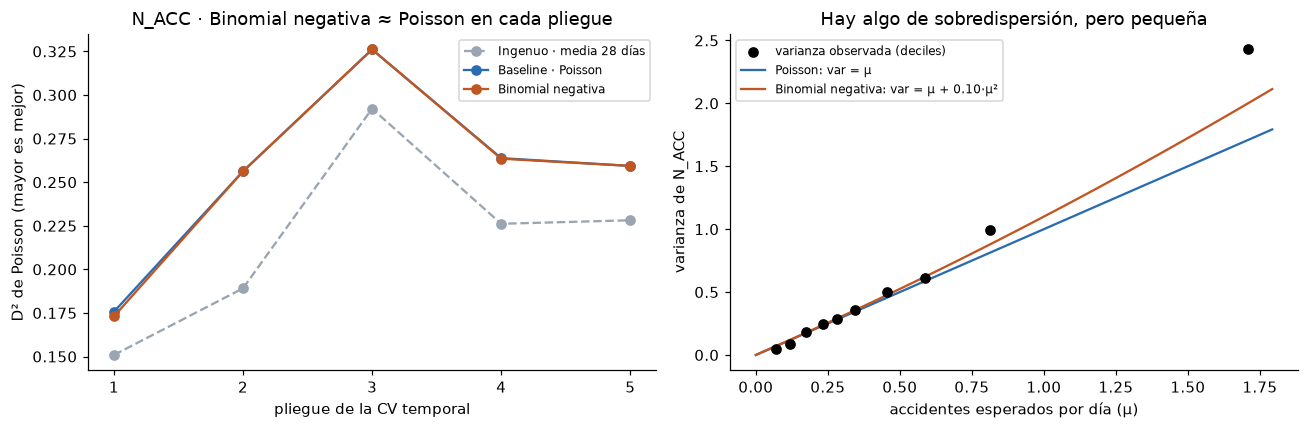

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(1, len(FOLDS1) + 1)
for (nombre, r_), est in zip(res.items(), [dict(color="#9aa5b1", ls="--"), dict(color="#2b6cb0"), dict(color="#c05621")]):
    axs[0].plot(x, r_.d2_poisson, marker="o", label=nombre, **est)
axs[0].set(xlabel="pliegue de la CV temporal", ylabel="D² de Poisson (mayor es mejor)", xticks=x,
           title="N_ACC · Binomial negativa ≈ Poisson en cada pliegue")
axs[0].legend(fontsize=8)

mu_bn = bn.predict(tr1[X1])
grupos = pd.qcut(mu_bn, 10, duplicates="drop")
g = pd.DataFrame({"mu": mu_bn, "y": y}).groupby(grupos, observed=True).agg(media=("mu", "mean"), varianza=("y", "var"))
lin = np.linspace(0, g.media.max() * 1.05, 50)
axs[1].scatter(g.media, g.varianza, color="k", zorder=3, label="varianza observada (deciles)")
axs[1].plot(lin, lin, color="#2b6cb0", label="Poisson: var = μ")
axs[1].plot(lin, lin + r.alpha_ * lin ** 2, color="#c05621", label=f"Binomial negativa: var = μ + {r.alpha_:.2f}·μ²")
axs[1].set(xlabel="accidentes esperados por día (μ)", ylabel="varianza de N_ACC",
           title="Hay algo de sobredispersión, pero pequeña")
axs[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(PLOTS / "modelo_09_t1_binomial_negativa.png", bbox_inches="tight")
plt.show()

In [9]:
f_metrics = ROOT / "results" / "metrics.csv"
nuevas = pd.DataFrame(FILAS)
previas = pd.read_csv(f_metrics)
clave = ["tarea", "modelo", "validacion"]
previas = previas[~previas.set_index(clave).index.isin(nuevas.set_index(clave).index)]   # reemplaza si ya existían
pd.concat([previas, nuevas], ignore_index=True).to_csv(f_metrics, index=False)
print(f"{len(nuevas)} filas guardadas en {f_metrics.name}")
nuevas.round(4)

12 filas guardadas en metrics.csv


,tarea,modelo,validacion,poisson_dev,d2_poisson,mae,rmse,pr_auc,roc_auc,brier,prevalencia
0,1_conteo_N_ACC,Ingenuo · media 28 días,CV temporal (5 pliegues),0.9984,0.2173,0.5464,0.7892,NaN,NaN,NaN,NaN
1,1_conteo_N_ACC,Baseline · Poisson,CV temporal (5 pliegues),0.9489,0.2562,0.5685,0.7923,NaN,NaN,NaN,NaN
2,1_conteo_N_ACC,Binomial negativa,CV temporal (5 pliegues),0.9496,0.2556,0.5689,0.7932,NaN,NaN,NaN,NaN
3,1_conteo_N_ACC,Ingenuo · media 28 días,holdout abr-sep 2021,1.0019,0.2775,0.6046,0.8365,NaN,NaN,NaN,NaN
4,1_conteo_N_ACC,Baseline · Poisson,holdout abr-sep 2021,1.0170,0.2665,0.5896,0.8504,NaN,NaN,NaN,NaN
5,1_conteo_N_ACC,Binomial negativa,holdout abr-sep 2021,1.0150,0.2680,0.5897,0.8492,NaN,NaN,NaN,NaN
6,1_clasificacion_HAY_FATAL,Ingenuo · fatales últimos 28 días,CV temporal (5 pliegues),NaN,NaN,NaN,NaN,0.1119,0.6775,0.0542,0.0584
7,1_clasificacion_HAY_FATAL,Baseline · Reg. logística,CV temporal (5 pliegues),NaN,NaN,NaN,NaN,0.1330,0.7041,0.0561,0.0584
8,1_clasificacion_HAY_FATAL,Binomial negativa (N_FATALES),CV temporal (5 pliegues),NaN,NaN,NaN,NaN,0.1303,0.7035,0.0546,0.0584
9,1_clasificacion_HAY_FATAL,Ingenuo · fatales últimos 28 días,holdout abr-sep 2021,NaN,NaN,NaN,NaN,0.1313,0.6887,0.0618,0.0676


## Lectura
- **N_ACC:** la binomial negativa empata con el Poisson del baseline (D² 0.256 en ambos en la CV temporal; diferencia −0.001, IC −0.002 a +0.000) y ambos superan al ingenuo de 28 días en los 5 pliegues (+0.038). En el holdout abr–sep 2021, ninguno de los dos supera al ingenuo (0.268 y 0.267 frente a 0.278).
- **Sobredispersión:** α = 0.10. Es estadísticamente significativa (razón de verosimilitudes = 19.4; AIC 16 799 frente a 16 816), pero pequeña: la varianza bruta de N_ACC es 1.66 veces su media, y casi toda esa variación la explican las variables (departamento, historia, calendario). Como la media predicha es casi la misma, la mejora en ajuste no se traduce en mejores pronósticos.
- **HAY_FATAL:** P(≥ 1 fatal) desde la binomial negativa de N_FATALES da una PR-AUC de 0.130 frente a 0.133 de la logística (empate). El α de N_FATALES ≈ 0: los fatales no tienen sobredispersión y el modelo se reduce a un Poisson.
- **Frente a Mhetre y Thube (2023):** ellos modelan un solo tramo (NH-48) con pocas variables, donde la sobredispersión queda sin explicar. Con el historial de cada departamento como variable, el Poisson del baseline basta.